# Revenue LP and geometric design blending

Piecewise concave revenue has an LP hypograph and resource shadow prices. Circuit blending uses simplex weights over six supplied designs; performance bounds are conditional on log-convex physical metrics.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Revenue witnesses

In [2]:
m=read("results/reference/convex/revenue/metrics.json")
assert m["duality_gap"]<1e-7
m

{'reference': {'solver': 'CLARABEL',
  'status': 'optimal',
  'objective': 192.49999999308372,
  'solver_seconds': 0.000119075},
 'highs_objective': 192.5,
 'solver_difference': 6.916280881341663e-09,
 'duality_gap': 0.0,
 'resource_violation': 0.0,
 'resource_shadow_prices': [0.0, 0.0, 0.03125000000000005, 0.90625, 0.71875],
 'first_resource_finite_difference': 0.0,
 'scope': 'Concave piecewise-linear revenue; resource duals are local marginal values, not a guarantee for arbitrary capacity changes.'}

## Geometric rather than arithmetic interpolation

In [3]:
values=np.array([4.,16.]); weights=np.array([.5,.5])
geometric=np.exp(np.log(values)@weights)
assert abs(geometric-8.)<1e-12
print("Geometric blend",geometric,"arithmetic",values@weights)

Geometric blend 7.999999999999999 arithmetic 10.0


## Supplied-design programs

In [4]:
pd.DataFrame(read("results/reference/convex/blend/metrics.json")["rows"])

,objective,simplex_residual,max_relative_spec_violation,common_log_margin,performance_upper_bounds,weights
0,feasible,0.000000e+00,0.000000e+00,0.000000e+00,"[59.999999999999986, 9.999999999999998, 48.625...","[0.06503671119536736, 0.3872660472121129, 0.0,..."
1,min_power,0.000000e+00,2.220446e-16,-4.440892e-16,"[59.540209036014474, 10.000000000000002, 48.68...","[0.0, 0.5246178853647909, 0.0, 0.4753821146352..."
2,max_common_log_margin,2.220446e-16,0.000000e+00,2.754750e-03,"[59.834942478676616, 9.972490413112766, 48.902...","[0.0, 0.5152549523399971, 0.0, 0.4847450476600..."


## Capacity and design plots

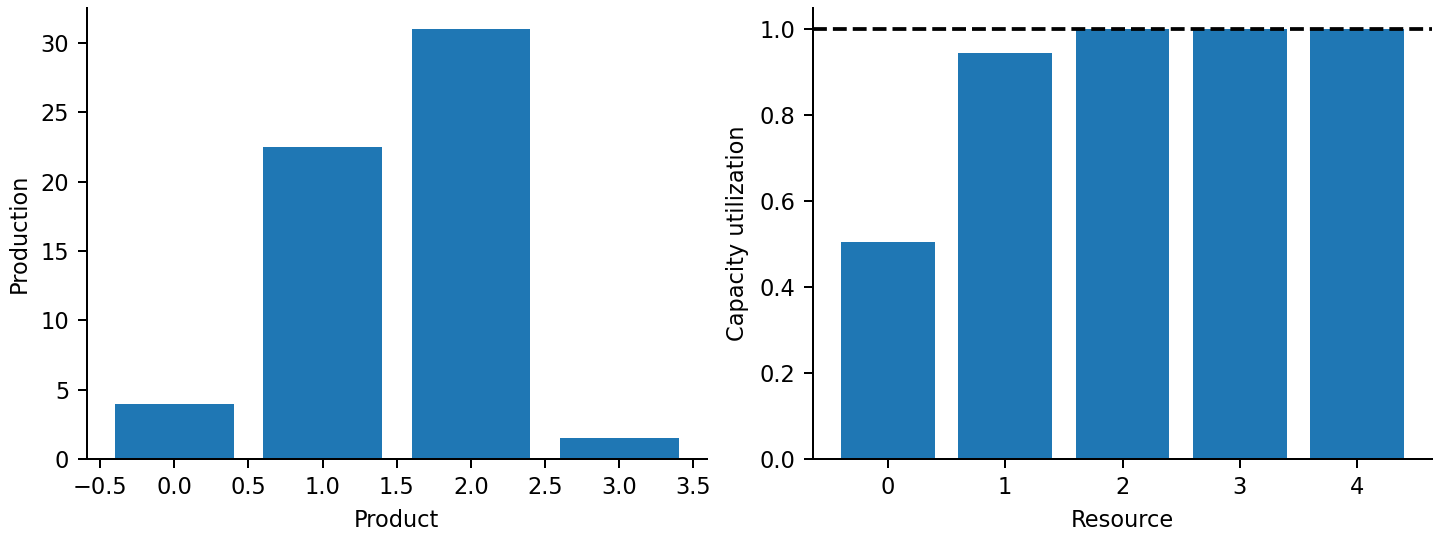

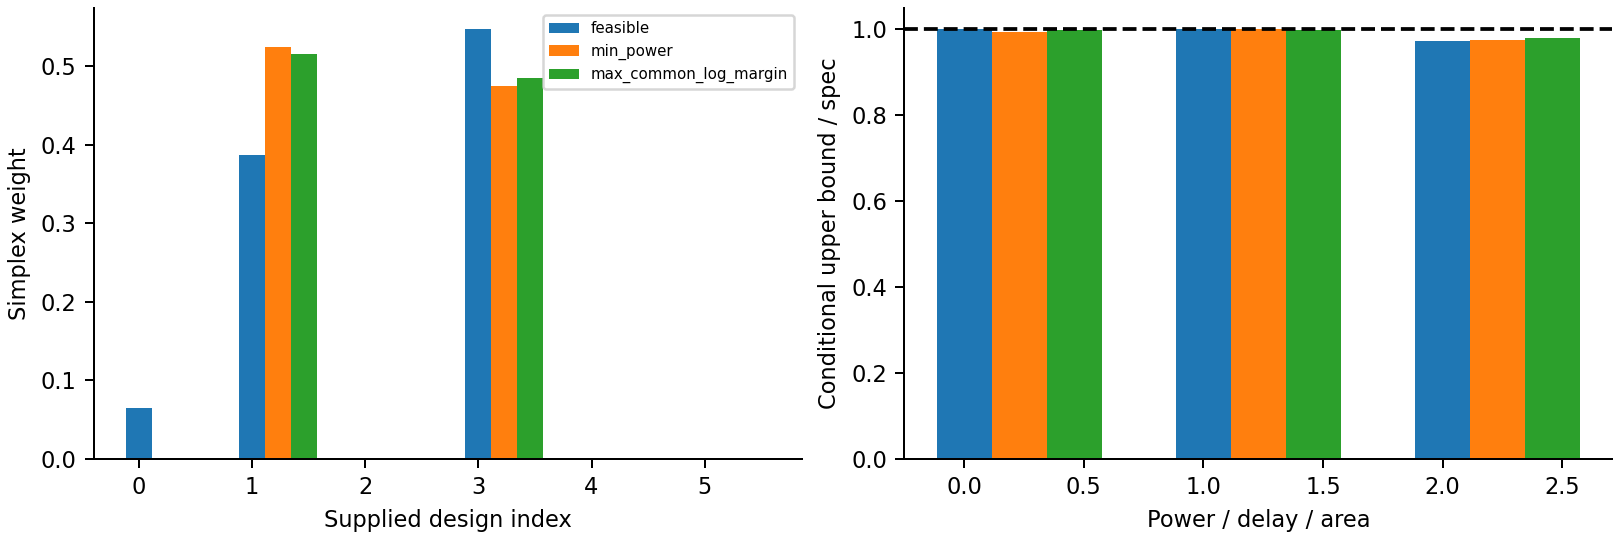

In [5]:
figure("revenue_capacity")
figure("geometric_blending")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.